Import thư viện và đặt số nút con, threshold

In [1]:
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

branching_factor, threshold = 10, 0.5
columns = ["Grocery", "Milk"]

Thêm và đọc dữ liệu

In [2]:
data = pd.read_csv("data/wholesale_customers.csv")
example_data = pd.read_csv("data/minh_hoa_birch.csv")
print("Wholesale customers:", data.shape)
print(data.head())
print("\nMinh họa Birch:", example_data.shape)
print(example_data.head())
print("\nThống kê hai đặc trưng:")
print(data[columns].describe().round(2))

Wholesale customers: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

Minh họa Birch: (20, 2)
   Grocery  Milk
0        1     2
1        1     4
2        2     3
3        2     2
4        5     8

Thống kê hai đặc trưng:
        Grocery      Milk
count    440.00    440.00
mean    7951.28   5796.27
std     9503.16   7380.38
min        3.00     55.00
25%     2153.00   1533.00
50%     4755.50   3627.00
75%    10655.75   7190.25
max    92780.00  73498.00


Tiền xử lý: Chuẩn hóa Z-Score

In [3]:
raw_data = data[columns].to_numpy(dtype=float)
X = StandardScaler().fit_transform(raw_data)
print("Các cột:", columns)
print("Trung bình sau chuẩn hóa:", X.mean(axis=0).round(4))
print("Độ lệch chuẩn sau chuẩn hóa:", X.std(axis=0).round(4))

Các cột: ['Grocery', 'Milk']
Trung bình sau chuẩn hóa: [-0.  0.]
Độ lệch chuẩn sau chuẩn hóa: [1. 1.]


Cài đặt CF, CF Entry, CF Node

In [4]:
class ClusteringFeature:
    def __init__(self, n, ls, ss):
        self.n = n
        self.ls = ls
        self.ss = ss

    def __add__(self, other):
        return ClusteringFeature(self.n + other.n, self.ls + other.ls,
                                 self.ss + other.ss)

    def centroid(self):
        return self.ls / self.n

    def radius(self):
        center = self.centroid()
        radius_squared = self.ss / self.n - np.dot(center, center)
        return float(np.sqrt(max(radius_squared, 0.0)))

    def to_dict(self):
        return {"N": self.n, "LS": self.ls.tolist(), "SS": self.ss,
                "centroid": self.centroid().tolist(), "radius": self.radius()}


class CFEntry:
    def __init__(self, cf, child=None):
        self.cf = cf
        self.child = child


class CFNode:
    def __init__(self, is_leaf, entries=None):
        self.is_leaf = is_leaf
        self.entries = [] if entries is None else entries

    def summary(self):
        total = self.entries[0].cf
        for entry in self.entries[1:]:
            total = total + entry.cf
        return total

Cài đặt CF Tree

In [5]:
class CFTree:
    def __init__(self, threshold=0.5, branching_factor=10, save_steps=False):
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.save_steps = save_steps
        self.root = CFNode(is_leaf=True)
        self.history = []

    def insert(self, point):
        point = np.asarray(point, dtype=float)
        cf = ClusteringFeature(1, point.copy(), float(np.dot(point, point)))
        if self.save_steps:
            self.history.append({
                "point": point.tolist(), "action": "new_entry",
                "before_cf": None, "after_cf": cf.to_dict(),
                "candidate_radius": 0.0, "splits": [],
                "before": self.statistics()
            })
        split = self.insert_cf(self.root, cf)
        if split is not None:
            self.root = CFNode(False, [CFEntry(node.summary(), node) for node in split])
            if self.save_steps:
                self.history[-1]["splits"].append("root")
        if self.save_steps:
            self.history[-1]["after"] = self.statistics()

    def insert_cf(self, node, point_cf):
        if not node.entries:
            node.entries.append(CFEntry(point_cf))
            return None
        centers = np.array([e.cf.centroid() for e in node.entries])
        index = int(np.argmin(np.sum((centers - point_cf.centroid()) ** 2, axis=1)))
        closest = node.entries[index]
        if node.is_leaf:
            merged = closest.cf + point_cf
            accepted = merged.radius() <= self.threshold
            if self.save_steps:
                self.history[-1].update({"action": "absorb" if accepted else "new_entry",
                               "before_cf": closest.cf.to_dict(),
                               "after_cf": (merged if accepted else point_cf).to_dict(),
                               "candidate_radius": merged.radius()})
            if accepted:
                closest.cf = merged
            else:
                node.entries.append(CFEntry(point_cf))
        else:
            split = self.insert_cf(closest.child, point_cf)
            if split is None:
                closest.cf = closest.child.summary()
            else:
                node.entries[index:index + 1] = [CFEntry(n.summary(), n) for n in split]
        if len(node.entries) > self.branching_factor:
            return self.split_node(node)
        return None

    def split_node(self, node):
        centers = np.array([e.cf.centroid() for e in node.entries])
        a, b = 0, 1
        farthest = -1
        for i in range(len(centers)):
            for j in range(i + 1, len(centers)):
                distance = np.sum((centers[i] - centers[j]) ** 2)
                if distance > farthest:
                    farthest = distance
                    a, b = i, j
        left, right = CFNode(node.is_leaf), CFNode(node.is_leaf)
        for i, entry in enumerate(node.entries):
            if i == a:
                left.entries.append(entry)
            elif i == b:
                right.entries.append(entry)
            elif (np.sum((centers[i] - centers[a]) ** 2)
                  <= np.sum((centers[i] - centers[b]) ** 2)):
                left.entries.append(entry)
            else:
                right.entries.append(entry)
        if self.save_steps:
            self.history[-1]["splits"].append("leaf" if node.is_leaf else "internal")
        return left, right

    def micro_clusters(self):
        result = []
        def visit(node):
            for entry in node.entries:
                if node.is_leaf:
                    result.append(entry.cf)
                else:
                    visit(entry.child)
        visit(self.root)
        return result

    def statistics(self):
        def visit(node):
            nodes, height = 1, 1
            for entry in node.entries:
                if entry.child is not None:
                    child_nodes, child_height = visit(entry.child)
                    nodes += child_nodes
                    height = max(height, child_height + 1)
            return nodes, height

        nodes, height = visit(self.root)
        return {"N": sum(entry.cf.n for entry in self.root.entries),
                "nodes": nodes, "height": height,
                "micro_clusters": len(self.micro_clusters())}


In [6]:
class Agglomerative:
    def __init__(self, n_clusters):
        self.n_clusters = n_clusters

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        groups = [[i] for i in range(len(X))]

        while len(groups) > self.n_clusters:
            centers = [X[group].mean(axis=0) for group in groups]
            best_cost = np.inf
            for i in range(len(groups)):
                for j in range(i + 1, len(groups)):
                    n_i, n_j = len(groups[i]), len(groups[j])
                    cost = n_i * n_j / (n_i + n_j) * np.sum(
                        (centers[i] - centers[j]) ** 2
                    )
                    if cost < best_cost:
                        best_cost = cost
                        a, b = i, j
            groups[a].extend(groups.pop(b))

        self.labels_ = np.empty(len(X), dtype=int)
        for label, group in enumerate(groups):
            self.labels_[group] = label
        return self


class Birch:
    def __init__(self, threshold=0.5, branching_factor=10,
                 save_steps=False, n_clusters=None):
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.save_steps = save_steps
        self.n_clusters = n_clusters

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.tree_ = CFTree(self.threshold, self.branching_factor, self.save_steps)

        for point in X:
            self.tree_.insert(point)

        micro_clusters = self.tree_.micro_clusters()
        self.subcluster_centers_ = np.array([
            cf.centroid() for cf in micro_clusters
        ])

        if self.n_clusters is None:
            self.subcluster_labels_ = np.arange(len(micro_clusters))
        else:
            self.subcluster_labels_ = Agglomerative(self.n_clusters).fit(
                self.subcluster_centers_
            ).labels_

        self.labels_ = self.predict(X)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        distances = np.zeros((len(X), len(self.subcluster_centers_)))

        for j, center in enumerate(self.subcluster_centers_):
            distances[:, j] = np.sum((X - center) ** 2, axis=1)

        nearest = distances.argmin(axis=1)
        return self.subcluster_labels_[nearest]

    def fit_predict(self, X):
        return self.fit(X).labels_

Minh họa trên tập minh_hoa_birch

In [7]:
example_X = example_data[columns].to_numpy(float)
example_model = Birch(threshold=1, branching_factor=2,
                      save_steps=True).fit(example_X)
rows = []
for step, record in enumerate(example_model.tree_.history, 1):
    before = record["before_cf"]
    after = record["after_cf"]
    rows.append({
        "step": step, "point": record["point"], "action": record["action"],
        "CF_nearest": None if before is None else (before["N"], before["LS"], before["SS"]),
        "N_after": after["N"], "LS_after": after["LS"], "SS_after": after["SS"],
        "centroid_after": after["centroid"], "radius_after": after["radius"],
        "candidate_radius": record["candidate_radius"]
    })

result = pd.DataFrame(rows).round(4)
print(result)

    step         point     action                 CF_nearest  N_after  \
0      1    [1.0, 2.0]  new_entry                       None        1   
1      2    [1.0, 4.0]     absorb       (1, [1.0, 2.0], 5.0)        2   
2      3    [2.0, 3.0]     absorb      (2, [2.0, 6.0], 22.0)        3   
3      4    [2.0, 2.0]     absorb      (3, [4.0, 9.0], 35.0)        4   
4      5    [5.0, 8.0]  new_entry     (4, [6.0, 11.0], 43.0)        1   
5      6   [5.0, 10.0]     absorb      (1, [5.0, 8.0], 89.0)        2   
6      7    [6.0, 9.0]     absorb   (2, [10.0, 18.0], 214.0)        3   
7      8    [6.0, 8.0]     absorb   (3, [16.0, 27.0], 331.0)        4   
8      9    [9.0, 3.0]  new_entry   (4, [22.0, 35.0], 431.0)        1   
9     10    [9.0, 5.0]     absorb      (1, [9.0, 3.0], 90.0)        2   
10    11   [10.0, 4.0]     absorb    (2, [18.0, 8.0], 196.0)        3   
11    12   [10.0, 3.0]     absorb   (3, [28.0, 12.0], 312.0)        4   
12    13  [13.0, 10.0]  new_entry   (4, [38.0, 15.0

Những lần tách nút

In [8]:
split_rows = []
for step, record in enumerate(example_model.tree_.history, 1):
    if record["splits"]:
        before = record["before"]
        after = record["after"]
        split_rows.append({
            "step": step, "point": record["point"], "splits": ", ".join(record["splits"]),
            "N_before": before["N"], "N_after": after["N"],
            "nodes_before": before["nodes"], "nodes_after": after["nodes"],
            "height_before": before["height"], "height_after": after["height"],
            "n_cf_before": before["micro_clusters"], "n_cf_after": after["micro_clusters"]
        })

result = pd.DataFrame(split_rows)
print(result)

   step         point                splits  N_before  N_after  nodes_before  \
0     9    [9.0, 3.0]            leaf, root         8        9             1   
1    13  [13.0, 10.0]  leaf, internal, root        12       13             3   

   nodes_after  height_before  height_after  n_cf_before  n_cf_after  
0            3              1             2            2           3  
1            6              2             3            3           4  


Phân cụm trên tập wholesale_customers

Thống kê cây: {'N': 440, 'nodes': 4, 'height': 2, 'micro_clusters': 22}
Số cụm sau gom toàn cục: 3


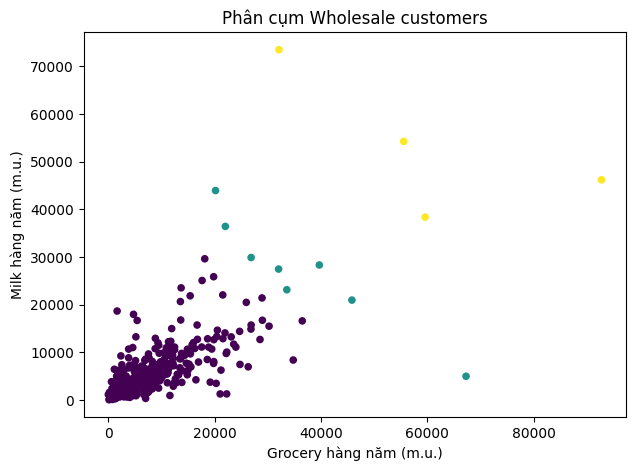

         n_customers  grocery_mean  milk_mean
cluster                                      
0                428       6941.60    4960.04
1                  8      35936.88   26891.88
2                  4      60015.75   53080.75


In [9]:
k = 3
model = Birch(threshold, branching_factor, n_clusters=k).fit(X)

print("Thống kê cây:", model.tree_.statistics())
print("Số cụm sau gom toàn cục:", len(np.unique(model.labels_)))

plt.figure(figsize=(7, 5))
plt.scatter(raw_data[:, 0], raw_data[:, 1], c=model.labels_, s=20)
plt.xlabel("Grocery hàng năm (m.u.)")
plt.ylabel("Milk hàng năm (m.u.)")
plt.title("Phân cụm Wholesale customers")
plt.show()

cluster_stats = data[columns].copy()
cluster_stats["cluster"] = model.labels_
cluster_stats = cluster_stats.groupby("cluster").agg(
    n_customers=("Grocery", "size"),
    grocery_mean=("Grocery", "mean"),
    milk_mean=("Milk", "mean")
)
print(cluster_stats.round(2))

So sánh

In [10]:
from sklearn.cluster import Birch as SklearnBirch, KMeans
from sklearn.metrics import silhouette_score

models = [
    ("BIRCH tự viết", Birch(threshold, branching_factor, n_clusters=k)),
    ("BIRCH sklearn", SklearnBirch(
        threshold=threshold,
        branching_factor=branching_factor,
        n_clusters=k
    )),
    ("K-Means", KMeans(n_clusters=k, random_state=42))
]

rows = []
for name, current_model in models:
    start = perf_counter()
    labels = current_model.fit_predict(X)
    seconds = perf_counter() - start

    cluster_sizes = np.unique(labels, return_counts=True)[1]
    n_clusters = len(cluster_sizes)
    score = np.nan
    if 2 <= n_clusters < len(X):
        score = silhouette_score(X, labels)

    rows.append({
        "algorithm": name,
        "seconds": seconds,
        "n_clusters": n_clusters,
        "cluster_sizes": cluster_sizes.tolist(),
        "Silhouette": score
    })

results = pd.DataFrame(rows)
print(results.round(4))

       algorithm  seconds  n_clusters  cluster_sizes  Silhouette
0  BIRCH tự viết   0.0231           3    [428, 8, 4]      0.7431
1  BIRCH sklearn   0.0419           3    [8, 4, 428]      0.7431
2        K-Means   1.9552           3  [329, 12, 99]      0.5935
